# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Faishal Muflih Irfanu Tsaqib
- **Email:** ds284b6y0548@student.devacademy.id / parikkce@gmail.com
- **ID Dicoding:** ds284b6y0548

## Menentukan Pertanyaan Bisnis

Proyek ini menganalisis data penyewaan sepeda (*bike sharing*) sistem Capital Bikeshare di Washington D.C. periode **1 Januari 2011 – 31 Desember 2012**. Pertanyaan bisnis disusun menggunakan kerangka **SMART** (*Specific, Measurable, Action-oriented, Relevant, Time-bound*).

- **Pertanyaan 1:** Pada jam berapa puncak rata-rata penyewaan sepeda per jam terjadi pada **hari kerja** dibandingkan **hari libur/akhir pekan** selama periode Januari 2011 – Desember 2012, dan berapa rata-rata jumlah sepeda yang disewa pada jam puncak tersebut, sebagai dasar penjadwalan redistribusi armada dan perawatan sepeda?
- **Pertanyaan 2:** Berapa persen penurunan rata-rata penyewaan sepeda harian saat kondisi cuaca **hujan/salju ringan** dibandingkan cuaca **cerah**, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah selama periode 2011 – 2012, sebagai dasar perencanaan kapasitas armada dan program promosi musiman?
- **Pertanyaan 3:** Berapa tingkat pertumbuhan total penyewaan sepeda tahun 2012 dibandingkan tahun 2011 (*Year-over-Year*) untuk setiap bulan, dan berapa kontribusi pengguna **casual** vs **registered** terhadap total penyewaan di masing-masing tahun, sebagai dasar strategi konversi pengguna casual menjadi member terdaftar?

| Elemen SMART | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| **Specific** | Pola per jam, hari kerja vs libur | Pengaruh cuaca & musim terhadap penyewaan harian | Pertumbuhan bulanan & tipe pengguna |
| **Measurable** | Jam puncak & rata-rata sepeda/jam | % penurunan & rata-rata sepeda/hari | % pertumbuhan YoY & % kontribusi pengguna |
| **Action-oriented** | Jadwal redistribusi & perawatan armada | Kapasitas armada & promosi musiman | Program konversi casual → member |
| **Relevant** | Ketersediaan sepeda saat permintaan tinggi | Perencanaan operasional berbasis cuaca | Pertumbuhan bisnis & loyalitas pelanggan |
| **Time-bound** | Jan 2011 – Des 2012 | 2011 – 2012 | 2011 vs 2012 per bulan |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Gaya visual yang konsisten untuk seluruh notebook
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})

# Palet warna: satu warna utama untuk menyorot informasi penting, abu-abu untuk konteks
HIGHLIGHT = "#1f6fb4"
SECOND = "#f28e2b"
NEUTRAL = "#c8ccd2"

pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 2.3.3 | seaborn 0.13.2


## Data Wrangling

### Gathering Data

Dataset terdiri dari dua tabel:
- `day.csv` → data penyewaan sepeda yang diagregasi **per hari** (731 hari).
- `hour.csv` → data penyewaan sepeda yang diagregasi **per jam**.

Kedua tabel dimuat ke dalam DataFrame.

In [2]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Ukuran day_df  :", day_df.shape)
print("Ukuran hour_df :", hour_df.shape)

Ukuran day_df  : (731, 16)
Ukuran hour_df : (17379, 17)


**Insight:**
- `day_df` berisi **731 baris × 16 kolom** (satu baris = satu hari, 1 Jan 2011 – 31 Des 2012), sedangkan `hour_df` berisi **17.379 baris × 17 kolom** (satu baris = satu jam), dengan tambahan kolom `hr` (jam 0–23).
- Variabel target adalah `cnt` (total penyewaan) yang merupakan penjumlahan `casual` (pengguna tidak terdaftar) dan `registered` (member). Data cuaca (`temp`, `atemp`, `hum`, `windspeed`) tersimpan dalam bentuk **ternormalisasi**, sedangkan variabel kategorikal (`season`, `weathersit`, `weekday`, dll.) tersimpan dalam bentuk **kode angka**.
- `hour_df` dipakai untuk menjawab pertanyaan pola per jam (Pertanyaan 1), sedangkan `day_df` dipakai untuk analisis harian, cuaca, musim, dan tren bulanan (Pertanyaan 2 & 3).

### Assessing Data

Pada tahap ini kualitas kedua tabel diperiksa dari sisi: tipe data, *missing value*, duplikasi, nilai tidak valid/tidak akurat, konsistensi antar kolom & antar tabel, kelengkapan data, dan *outlier*.

#### Menilai tabel `day_df`

In [5]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
print("Jumlah missing value per kolom:")
print(day_df.isna().sum())
print("\nJumlah data duplikat:", day_df.duplicated().sum())

Jumlah missing value per kolom:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Jumlah data duplikat: 0


In [7]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
# Cek invalid/inaccurate value: kelembapan 0% secara fisik tidak masuk akal untuk kondisi cuaca normal
day_df[day_df["hum"] == 0]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
68,69,2011-03-10,1,0,3,0,4,1,3,0.389091,0.385668,0.0,0.261877,46,577,623


In [9]:
# Cek konsistensi: cnt seharusnya = casual + registered
print("Baris day_df dengan cnt != casual + registered :", (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())

# Cek kesesuaian kode kategori dengan dokumentasi dataset
for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(f"{col:<11}: {sorted(day_df[col].unique())}")

Baris day_df dengan cnt != casual + registered : 0
season     : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr         : [np.int64(0), np.int64(1)]
mnth       : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday    : [np.int64(0), np.int64(1)]
weekday    : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday : [np.int64(0), np.int64(1)]
weathersit : [np.int64(1), np.int64(2), np.int64(3)]


#### Menilai tabel `hour_df`

In [10]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [11]:
print("Jumlah missing value per kolom:")
print(hour_df.isna().sum())
print("\nJumlah data duplikat:", hour_df.duplicated().sum())
print("Jumlah duplikat kombinasi (dteday, hr):", hour_df.duplicated(subset=["dteday", "hr"]).sum())

Jumlah missing value per kolom:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Jumlah data duplikat: 0
Jumlah duplikat kombinasi (dteday, hr): 0


In [12]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [13]:
# Cek kelengkapan data per jam: seharusnya setiap hari memiliki 24 baris
expected_rows = hour_df["dteday"].nunique() * 24
print("Jumlah baris seharusnya :", expected_rows)
print("Jumlah baris aktual     :", len(hour_df))
print("Jam yang tidak tercatat :", expected_rows - len(hour_df),
      f"({(expected_rows - len(hour_df)) / expected_rows:.2%})")

rows_per_day = hour_df.groupby("dteday").size()
print("\nJumlah hari yang tidak memiliki 24 jam data:", (rows_per_day < 24).sum())
rows_per_day[rows_per_day < 24].sort_values().head(5)

Jumlah baris seharusnya : 17544
Jumlah baris aktual     : 17379
Jam yang tidak tercatat : 165 (0.94%)

Jumlah hari yang tidak memiliki 24 jam data: 76


dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
2011-01-18    12
2011-01-26    16
dtype: int64

In [14]:
# Invalid value: kelembapan 0% pada data per jam
print("Baris hour_df dengan hum = 0 :", (hour_df["hum"] == 0).sum())
print("Tanggal:", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

# Konsistensi antar tabel: total cnt per hari pada hour_df harus sama dengan cnt di day_df
daily_from_hour = hour_df.groupby("dteday")["cnt"].sum()
compare = day_df.set_index("dteday")["cnt"].eq(daily_from_hour)
print("\nHari dengan total cnt hour_df ≠ day_df :", (~compare).sum())
print("Baris hour_df dengan cnt != casual + registered :", (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum())

Baris hour_df dengan hum = 0 : 22
Tanggal: ['2011-03-10']

Hari dengan total cnt hour_df ≠ day_df : 0
Baris hour_df dengan cnt != casual + registered : 0


#### Deteksi *outlier* dengan metode IQR

In [15]:
def count_outliers_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), lower, upper

outlier_summary = []
for col in ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]:
    n, lo, up = count_outliers_iqr(day_df[col])
    outlier_summary.append({"kolom": col, "jumlah_outlier": n, "batas_bawah": round(lo, 3), "batas_atas": round(up, 3)})
pd.DataFrame(outlier_summary)

,kolom,jumlah_outlier,batas_bawah,batas_atas
0,temp,0,-0.140,1.133
1,atemp,0,-0.068,1.015
2,hum,2,0.205,1.046
3,windspeed,13,-0.012,0.381
4,casual,44,-855.250,2266.750
5,registered,0,-922.250,8195.750
6,cnt,0,-1054.000,10162.000


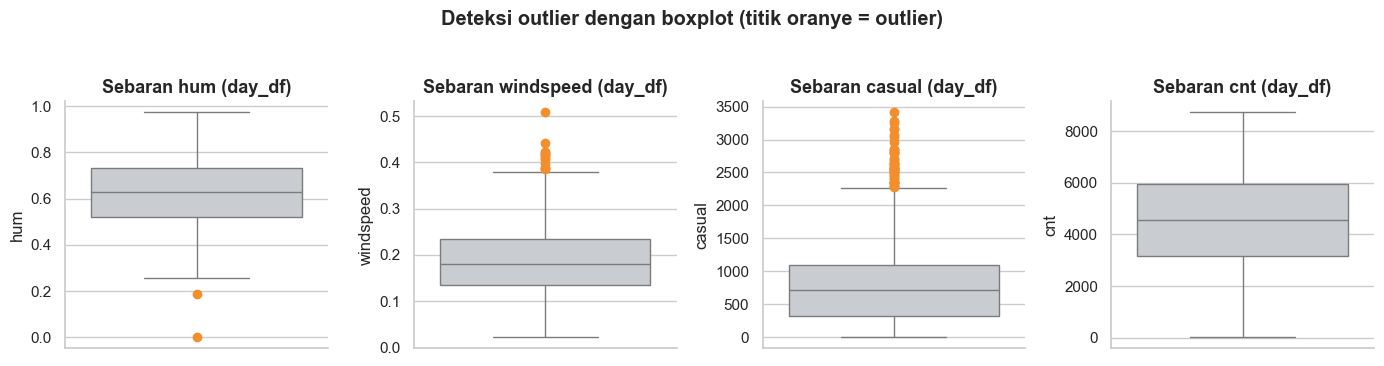

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, ["hum", "windspeed", "casual", "cnt"]):
    sns.boxplot(y=day_df[col], ax=ax, color=NEUTRAL, flierprops={"markerfacecolor": SECOND, "markeredgecolor": SECOND})
    ax.set_title(f"Sebaran {col} (day_df)")
    ax.set_ylabel(col)
fig.suptitle("Deteksi outlier dengan boxplot (titik oranye = outlier)", y=1.04, fontweight="bold")
plt.tight_layout()

In [17]:
# Melihat hari dengan penyewaan paling rendah (cek apakah outlier tersebut valid)
day_df.nsmallest(3, "cnt")[["dteday", "season", "weathersit", "temp", "hum", "windspeed", "cnt"]]

,dteday,season,weathersit,temp,hum,windspeed,cnt
667,2012-10-29,4,3,0.440000,0.880000,0.358200,22
26,2011-01-27,1,1,0.195000,0.687500,0.113837,431
725,2012-12-26,1,3,0.243333,0.823333,0.316546,441


**Insight:**
- **Tidak ada *missing value* dan tidak ada data duplikat** pada kedua tabel, termasuk tidak ada duplikasi kombinasi tanggal–jam.
- **Tipe data tidak tepat (*invalid data type*):** kolom `dteday` bertipe `object/string`, seharusnya `datetime`. Kolom kategorikal (`season`, `yr`, `mnth`, `weekday`, `weathersit`, `holiday`, `workingday`) masih berupa kode angka sehingga sulit diinterpretasikan.
- **Nilai tidak akurat (*inaccurate value*):** terdapat kelembapan (`hum`) bernilai **0** pada tanggal **2011-03-10** (1 baris di `day_df`, 22 baris di `hour_df`). Kelembapan 0% di hari hujan/mendung tidak masuk akal secara fisik sehingga kemungkinan besar merupakan kesalahan sensor.
- **Data tidak lengkap:** `hour_df` hanya memiliki **17.379 dari 17.544** jam yang seharusnya (**165 jam tidak tercatat, ±0,94%**) dan tersebar di 76 hari. Namun total `cnt` per hari di `hour_df` **identik** dengan `day_df`, sehingga jam yang hilang kemungkinan besar adalah jam tanpa penyewaan atau saat sistem tidak beroperasi.
- **Konsistensi:** `cnt = casual + registered` terpenuhi di seluruh baris, dan semua kode kategori sesuai dokumentasi.
- **Outlier:** terdeteksi outlier pada `casual` (44 hari), `windspeed` (13 hari), dan `hum` (2 hari). Hari dengan penyewaan terendah (2012-10-29, hanya 22 sepeda) bertepatan dengan **Badai Sandy** di Washington D.C., sehingga outlier ini merupakan **peristiwa nyata**, bukan kesalahan data.

**Rencana cleaning:**
1. Mengubah `dteday` menjadi tipe `datetime`.
2. Mengganti nilai `hum = 0` dengan rata-rata kelembapan bulan Maret 2011 (imputasi).
3. Mengubah kode angka menjadi label kategori yang mudah dibaca dan mengubah tipe datanya menjadi `category`.
4. Mengembalikan nilai cuaca ternormalisasi ke satuan aslinya (°C, %, km/jam) agar mudah dipahami.
5. Jam yang tidak tercatat dan outlier **dipertahankan** (tidak dihapus/diimputasi) karena merepresentasikan kondisi nyata.

### Cleaning Data

#### 1. Mengubah tipe data `dteday` menjadi `datetime`

In [18]:
for df in [day_df, hour_df]:
    df["dteday"] = pd.to_datetime(df["dteday"])

print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[ns] datetime64[ns]


#### 2. Menangani nilai kelembapan (`hum`) yang tidak akurat
Nilai `hum = 0` diubah menjadi `NaN`, lalu diisi dengan rata-rata kelembapan bulan Maret 2011 (bulan & tahun yang sama) agar tetap merepresentasikan kondisi musiman.

In [19]:
for df in [day_df, hour_df]:
    df["hum"] = df["hum"].replace(0, np.nan)
    march_2011 = (df["yr"] == 0) & (df["mnth"] == 3)
    df.loc[march_2011, "hum"] = df.loc[march_2011, "hum"].fillna(df.loc[march_2011, "hum"].mean())

print("Sisa hum = 0 / NaN pada day_df :", ((day_df["hum"] == 0) | day_df["hum"].isna()).sum())
print("Sisa hum = 0 / NaN pada hour_df:", ((hour_df["hum"] == 0) | hour_df["hum"].isna()).sum())
day_df.loc[day_df["dteday"] == "2011-03-10", ["dteday", "hum"]]

Sisa hum = 0 / NaN pada day_df : 0
Sisa hum = 0 / NaN pada hour_df: 0


,dteday,hum
68,2011-03-10,0.588394


#### 3. Mengubah kode angka menjadi label kategori yang mudah dibaca

In [20]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {1: "Cerah/Berawan", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan", 4: "Hujan Lebat/Badai"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

def label_categories(df):
    df["season"] = pd.Categorical(df["season"].map(season_map), categories=list(season_map.values()), ordered=True)
    df["weathersit"] = pd.Categorical(df["weathersit"].map(weather_map), categories=list(weather_map.values()), ordered=True)
    df["weekday"] = pd.Categorical(df["weekday"].map(weekday_map),
                                   categories=["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"], ordered=True)
    df["mnth"] = pd.Categorical(df["mnth"].map(month_map), categories=list(month_map.values()), ordered=True)
    df["yr"] = df["yr"].map({0: 2011, 1: 2012})
    df["holiday"] = df["holiday"].map({0: "Bukan Libur", 1: "Libur"}).astype("category")
    df["workingday"] = df["workingday"].map({0: "Libur/Akhir Pekan", 1: "Hari Kerja"}).astype("category")
    return df

day_df = label_categories(day_df)
hour_df = label_categories(hour_df)
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,Jan,Bukan Libur,Sabtu,Libur/Akhir Pekan,Berkabut/Mendung,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,Jan,Bukan Libur,Minggu,Libur/Akhir Pekan,Berkabut/Mendung,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,Jan,Bukan Libur,Senin,Hari Kerja,Cerah/Berawan,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,Jan,Bukan Libur,Selasa,Hari Kerja,Cerah/Berawan,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,Jan,Bukan Libur,Rabu,Hari Kerja,Cerah/Berawan,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### 4. Mengembalikan nilai cuaca ke satuan asli dan merapikan nama kolom
Sesuai dokumentasi dataset: `temp` dibagi 41, `atemp` dibagi 50, `hum` dibagi 100, dan `windspeed` dibagi 67.

In [21]:
def denormalize_and_rename(df):
    df["temp"] = (df["temp"] * 41).round(2)
    df["atemp"] = (df["atemp"] * 50).round(2)
    df["hum"] = (df["hum"] * 100).round(2)
    df["windspeed"] = (df["windspeed"] * 67).round(2)
    return df.rename(columns={
        "dteday": "date", "yr": "year", "mnth": "month", "hr": "hour",
        "weathersit": "weather", "temp": "temp_c", "atemp": "feels_like_c",
        "hum": "humidity", "windspeed": "windspeed_kmh", "cnt": "total_rentals"})

day_df = denormalize_and_rename(day_df)
hour_df = denormalize_and_rename(hour_df)
day_df.head()

,instant,date,season,year,month,holiday,weekday,workingday,weather,temp_c,feels_like_c,humidity,windspeed_kmh,casual,registered,total_rentals
0,1,2011-01-01,Spring,2011,Jan,Bukan Libur,Sabtu,Libur/Akhir Pekan,Berkabut/Mendung,14.11,18.18,80.58,10.75,331,654,985
1,2,2011-01-02,Spring,2011,Jan,Bukan Libur,Minggu,Libur/Akhir Pekan,Berkabut/Mendung,14.90,17.69,69.61,16.65,131,670,801
2,3,2011-01-03,Spring,2011,Jan,Bukan Libur,Senin,Hari Kerja,Cerah/Berawan,8.05,9.47,43.73,16.64,120,1229,1349
3,4,2011-01-04,Spring,2011,Jan,Bukan Libur,Selasa,Hari Kerja,Cerah/Berawan,8.20,10.61,59.04,10.74,108,1454,1562
4,5,2011-01-05,Spring,2011,Jan,Bukan Libur,Rabu,Hari Kerja,Cerah/Berawan,9.31,11.46,43.70,12.52,82,1518,1600


In [22]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        731 non-null    int64         
 1   date           731 non-null    datetime64[ns]
 2   season         731 non-null    category      
 3   year           731 non-null    int64         
 4   month          731 non-null    category      
 5   holiday        731 non-null    category      
 6   weekday        731 non-null    category      
 7   workingday     731 non-null    category      
 8   weather        731 non-null    category      
 9   temp_c         731 non-null    float64       
 10  feels_like_c   731 non-null    float64       
 11  humidity       731 non-null    float64       
 12  windspeed_kmh  731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  total_rentals  731 non-

In [23]:
hour_df[["temp_c", "feels_like_c", "humidity", "windspeed_kmh", "total_rentals"]].describe()

,temp_c,feels_like_c,humidity,windspeed_kmh,total_rentals
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,20.376474,23.788484,62.797293,12.736233,189.463088
std,7.894801,8.592587,19.163842,8.196891,181.387599
min,0.820000,0.000000,8.000000,0.000000,1.000000
25%,13.940000,16.660000,48.000000,7.000000,40.000000
50%,20.500000,24.240000,63.000000,13.000000,142.000000
75%,27.060000,31.060000,78.000000,17.000000,281.000000
max,41.000000,50.000000,100.000000,57.000000,977.000000


**Insight:**
- Kolom `date` kini bertipe `datetime64` sehingga dapat dipakai untuk analisis berbasis waktu (resampling bulanan, filter rentang tanggal di dashboard).
- Nilai kelembapan 0% pada 2011-03-10 telah diganti dengan rata-rata kelembapan Maret 2011, sehingga **tidak ada lagi nilai tidak akurat** pada kolom kelembapan.
- Seluruh kode angka telah diubah menjadi **label kategori berurutan** (`ordered category`), sehingga grafik akan otomatis tersusun sesuai urutan logis (Spring → Winter, Jan → Des, Senin → Minggu).
- Data cuaca kini dalam satuan asli: suhu **±0,8–41 °C**, kelembapan **±8–100%**, dan kecepatan angin **0–57 km/jam**, sehingga insight lebih mudah dipahami oleh stakeholder.
- Jam yang tidak tercatat dan outlier dipertahankan karena merepresentasikan kondisi nyata (misalnya Badai Sandy), sehingga data siap dieksplorasi.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif data harian

In [24]:
day_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
instant,731.0,NaN,NaN,NaN,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
date,731,NaN,NaN,NaN,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731,4,Fall,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,731.0,NaN,NaN,NaN,2011.500684,2011.0,2011.0,2012.0,2012.0,2012.0,0.500342
month,731,12,Jan,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
holiday,731,2,Bukan Libur,710,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekday,731,7,Senin,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
workingday,731,2,Hari Kerja,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather,731,3,Cerah/Berawan,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp_c,731.0,NaN,NaN,NaN,20.310821,2.42,13.82,20.43,26.875,35.33,7.505177


### Explore pola penyewaan per jam: hari kerja vs libur/akhir pekan (Pertanyaan 1)

In [25]:
hourly_pattern = hour_df.groupby(["hour", "workingday"], observed=True)["total_rentals"].mean().unstack().round(1)
hourly_pattern

workingday,Hari Kerja,Libur/Akhir Pekan
hour,,
0,36.8,90.8
1,16.6,69.5
2,8.7,53.2
3,4.9,25.8
4,5.4,8.3
5,24.9,8.7
6,102.5,18.7
7,290.6,43.4
8,477.0,105.7


In [26]:
peak_hours = pd.DataFrame({
    "jam_puncak": hourly_pattern.idxmax(),
    "rata2_sewa_saat_puncak": hourly_pattern.max().round(0),
    "jam_terendah": hourly_pattern.idxmin(),
    "rata2_sewa_saat_terendah": hourly_pattern.min().round(0),
})
peak_hours

,jam_puncak,rata2_sewa_saat_puncak,jam_terendah,rata2_sewa_saat_terendah
workingday,,,,
Hari Kerja,17,525.0,3,5.0
Libur/Akhir Pekan,13,373.0,4,8.0


In [27]:
# Tiga jam tersibuk untuk masing-masing tipe hari
for col in hourly_pattern.columns:
    top3 = hourly_pattern[col].nlargest(3)
    print(f"{col:<18}: " + ", ".join(f"jam {h:02d}.00 ({v:.0f} sepeda)" for h, v in top3.items()))

Hari Kerja        : jam 17.00 (525 sepeda), jam 18.00 (492 sepeda), jam 08.00 (477 sepeda)
Libur/Akhir Pekan : jam 13.00 (373 sepeda), jam 12.00 (366 sepeda), jam 14.00 (365 sepeda)


In [28]:
hour_df.groupby("workingday", observed=True).agg(
    rata2_casual=("casual", "mean"),
    rata2_registered=("registered", "mean"),
    rata2_total=("total_rentals", "mean"),
).round(1)

,rata2_casual,rata2_registered,rata2_total
workingday,,,
Hari Kerja,25.6,167.6,193.2
Libur/Akhir Pekan,57.4,124.0,181.4


**Insight:**
- Pada **hari kerja**, pola penyewaan bersifat **bimodal** dengan puncak pada jam **08.00 (±477 sepeda/jam)** dan **17.00 (±525 sepeda/jam)**, lalu **18.00 (±492)** — sejalan dengan jam berangkat dan pulang kerja/sekolah (*commuting*).
- Pada **hari libur/akhir pekan**, pola bersifat **unimodal**: penyewaan meningkat bertahap dan memuncak di siang hari pada jam **13.00 (±373 sepeda/jam)**, dengan rentang tinggi stabil pada jam 11.00–16.00. Ini menandakan penggunaan untuk **rekreasi**.
- Jam paling sepi untuk kedua tipe hari ada di **dini hari (03.00–04.00)** dengan rata-rata di bawah 10 sepeda/jam — waktu ideal untuk perawatan armada.
- Rata-rata pengguna *casual* per jam di hari libur jauh lebih tinggi daripada di hari kerja, sedangkan pengguna *registered* mendominasi hari kerja.

### Explore pengaruh cuaca dan musim terhadap penyewaan harian (Pertanyaan 2)

In [29]:
weather_stats = day_df.groupby("weather", observed=True).agg(
    jumlah_hari=("date", "count"),
    rata2_sewa_harian=("total_rentals", "mean"),
    median_sewa_harian=("total_rentals", "median"),
).round(0)
weather_stats["selisih_vs_cerah_%"] = ((weather_stats["rata2_sewa_harian"] /
                                         weather_stats.loc["Cerah/Berawan", "rata2_sewa_harian"] - 1) * 100).round(1)
weather_stats

,jumlah_hari,rata2_sewa_harian,median_sewa_harian,selisih_vs_cerah_%
weather,,,,
Cerah/Berawan,463,4877.0,4844.0,0.0
Berkabut/Mendung,247,4036.0,4040.0,-17.2
Hujan/Salju Ringan,21,1803.0,1817.0,-63.0


In [30]:
season_stats = day_df.groupby("season", observed=True).agg(
    jumlah_hari=("date", "count"),
    rata2_sewa_harian=("total_rentals", "mean"),
    rata2_suhu_c=("temp_c", "mean"),
).round(1).sort_values("rata2_sewa_harian", ascending=False)
season_stats

,jumlah_hari,rata2_sewa_harian,rata2_suhu_c
season,,,
Fall,188,5644.3,29.0
Summer,184,4992.3,22.3
Winter,178,4728.2,17.3
Spring,181,2604.1,12.2


In [31]:
# Kombinasi musim x cuaca
pd.pivot_table(day_df, values="total_rentals", index="season", columns="weather",
               aggfunc="mean", observed=True).round(0)

weather,Cerah/Berawan,Berkabut/Mendung,Hujan/Salju Ringan
season,,,
Spring,2811.0,2357.0,935.0
Summer,5549.0,4237.0,1169.0
Fall,5878.0,5222.0,2752.0
Winter,5044.0,4654.0,1962.0


In [32]:
# Korelasi variabel cuaca dengan jumlah penyewaan harian
day_df[["temp_c", "feels_like_c", "humidity", "windspeed_kmh", "casual", "registered", "total_rentals"]].corr().round(2)

,temp_c,feels_like_c,humidity,windspeed_kmh,casual,registered,total_rentals
temp_c,1.00,0.99,0.13,-0.16,0.54,0.54,0.63
feels_like_c,0.99,1.00,0.14,-0.18,0.54,0.54,0.63
humidity,0.13,0.14,1.00,-0.25,-0.08,-0.10,-0.11
windspeed_kmh,-0.16,-0.18,-0.25,1.00,-0.17,-0.22,-0.23
casual,0.54,0.54,-0.08,-0.17,1.00,0.40,0.67
registered,0.54,0.54,-0.10,-0.22,0.40,1.00,0.95
total_rentals,0.63,0.63,-0.11,-0.23,0.67,0.95,1.00


**Insight:**
- Rata-rata penyewaan harian saat **cuaca cerah ±4.877 sepeda**, saat **berkabut/mendung ±4.036 (−17,2%)**, dan saat **hujan/salju ringan hanya ±1.803 sepeda (−63,0%)**. Kategori hujan lebat/badai tidak muncul pada data harian (hanya 3 jam pada data per jam).
- Musim dengan rata-rata penyewaan harian tertinggi adalah **Fall/gugur (±5.644 sepeda/hari)**, diikuti Summer (±4.992), Winter (±4.728), dan terendah **Spring (±2.604 sepeda/hari)** — kurang dari setengah musim Fall.
- Penurunan akibat hujan terjadi di semua musim, sehingga cuaca dan musim sama-sama memengaruhi permintaan.
- **Suhu** memiliki korelasi positif cukup kuat dengan total penyewaan (r ≈ 0,63), sedangkan kelembapan dan kecepatan angin berkorelasi negatif lemah. Rendahnya penyewaan di musim Spring sejalan dengan suhu rata-rata paling dingin (±12 °C) pada musim tersebut di dataset ini.

### Explore pertumbuhan penyewaan 2011 vs 2012 dan tipe pengguna (Pertanyaan 3)

In [33]:
yearly = day_df.groupby("year")[["casual", "registered", "total_rentals"]].sum()
yearly["%casual"] = (yearly["casual"] / yearly["total_rentals"] * 100).round(1)
yearly["%registered"] = (yearly["registered"] / yearly["total_rentals"] * 100).round(1)
yearly

,casual,registered,total_rentals,%casual,%registered
year,,,,,
2011,247252,995851,1243103,19.9,80.1
2012,372765,1676811,2049576,18.2,81.8


In [34]:
growth_total = (yearly.loc[2012, "total_rentals"] / yearly.loc[2011, "total_rentals"] - 1) * 100
growth_casual = (yearly.loc[2012, "casual"] / yearly.loc[2011, "casual"] - 1) * 100
growth_registered = (yearly.loc[2012, "registered"] / yearly.loc[2011, "registered"] - 1) * 100
added = yearly.loc[2012] - yearly.loc[2011]
print(f"Pertumbuhan total penyewaan 2012 vs 2011 : {growth_total:.1f}%")
print(f"Pertumbuhan pengguna casual              : {growth_casual:.1f}%")
print(f"Pertumbuhan pengguna registered          : {growth_registered:.1f}%")
print(f"Kontribusi registered terhadap tambahan penyewaan: {added['registered'] / added['total_rentals'] * 100:.1f}%")

Pertumbuhan total penyewaan 2012 vs 2011 : 64.9%
Pertumbuhan pengguna casual              : 50.8%
Pertumbuhan pengguna registered          : 68.4%
Kontribusi registered terhadap tambahan penyewaan: 84.4%


In [35]:
monthly = day_df.pivot_table(values="total_rentals", index="month", columns="year", aggfunc="sum", observed=True)
monthly["growth_yoy_%"] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly

year,2011,2012,growth_yoy_%
month,,,
Jan,38189,96744,153.3
Feb,48215,103137,113.9
Mar,64045,164875,157.4
Apr,94870,174224,83.6
Mei,135821,195865,44.2
Jun,143512,202830,41.3
Jul,141341,203607,44.1
Agu,136691,214503,56.9
Sep,127418,218573,71.5


In [36]:
print("Bulan dengan pertumbuhan YoY tertinggi:", monthly["growth_yoy_%"].idxmax(), f"({monthly['growth_yoy_%'].max()}%)")
print("Bulan dengan pertumbuhan YoY terendah :", monthly["growth_yoy_%"].idxmin(), f"({monthly['growth_yoy_%'].min()}%)")
print("Bulan dengan total penyewaan tertinggi 2011:", monthly[2011].idxmax(), "| 2012:", monthly[2012].idxmax())

Bulan dengan pertumbuhan YoY tertinggi: Mar (157.4%)
Bulan dengan pertumbuhan YoY terendah : Jun (41.3%)
Bulan dengan total penyewaan tertinggi 2011: Jun | 2012: Sep


In [37]:
day_df.groupby("workingday", observed=True)[["casual", "registered"]].mean().round(0)

,casual,registered
workingday,,
Hari Kerja,607.0,3978.0
Libur/Akhir Pekan,1371.0,2959.0


**Insight:**
- Total penyewaan naik dari **1.243.103 (2011)** menjadi **2.049.576 (2012)**, atau tumbuh **±64,9% YoY**.
- **Seluruh 12 bulan** di 2012 lebih tinggi dari 2011. Pertumbuhan tertinggi terjadi di **Maret (+157,4%)** dan Januari (+153,3%), sedangkan terendah di **Juni (+41,3%)**. Puncak penyewaan bergeser dari **Juni (2011)** ke **September (2012)**.
- Pengguna **registered** menyumbang **±80%** total penyewaan di kedua tahun (80,1% → 81,8%) dan menyumbang **±84%** dari tambahan penyewaan 2012 — mesin utama pertumbuhan bisnis.
- Pengguna **casual** hanya ±18–20% tetapi rata-ratanya **2,3× lebih tinggi di hari libur** (±1.371 vs ±607 per hari), sehingga mereka adalah segmen rekreasi yang potensial dikonversi menjadi member.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Pada jam berapa puncak rata-rata penyewaan sepeda per jam terjadi pada hari kerja dibandingkan hari libur/akhir pekan selama Januari 2011 – Desember 2012?

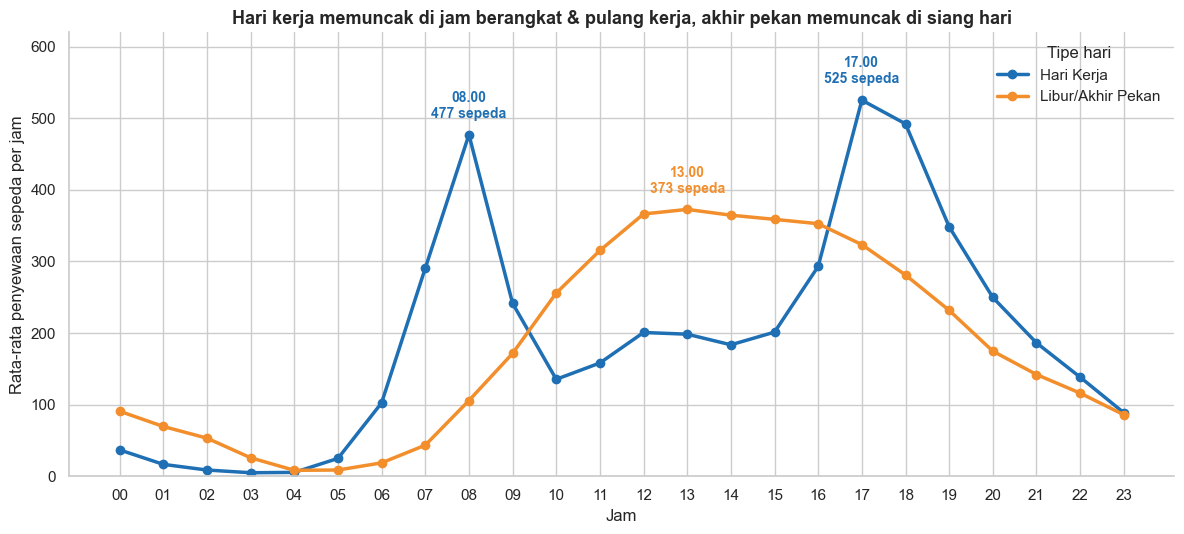

In [38]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(hourly_pattern.index, hourly_pattern["Hari Kerja"], marker="o", color=HIGHLIGHT, linewidth=2.5, label="Hari Kerja")
ax.plot(hourly_pattern.index, hourly_pattern["Libur/Akhir Pekan"], marker="o", color=SECOND, linewidth=2.5, label="Libur/Akhir Pekan")

# Anotasi jam puncak
for col, color, offset in [("Hari Kerja", HIGHLIGHT, (0, 12)), ("Libur/Akhir Pekan", SECOND, (0, 12))]:
    s = hourly_pattern[col]
    peaks = [s.idxmax()] if col == "Libur/Akhir Pekan" else [s.loc[:12].idxmax(), s.loc[12:].idxmax()]
    for h in peaks:
        ax.annotate(f"{h:02d}.00\n{s[h]:.0f} sepeda", (h, s[h]), textcoords="offset points", xytext=offset,
                    ha="center", fontsize=10, fontweight="bold", color=color)

ax.set_title("Hari kerja memuncak di jam berangkat & pulang kerja, akhir pekan memuncak di siang hari")
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata penyewaan sepeda per jam")
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)])
ax.set_ylim(0, 620)
ax.legend(title="Tipe hari", frameon=False)
plt.tight_layout()

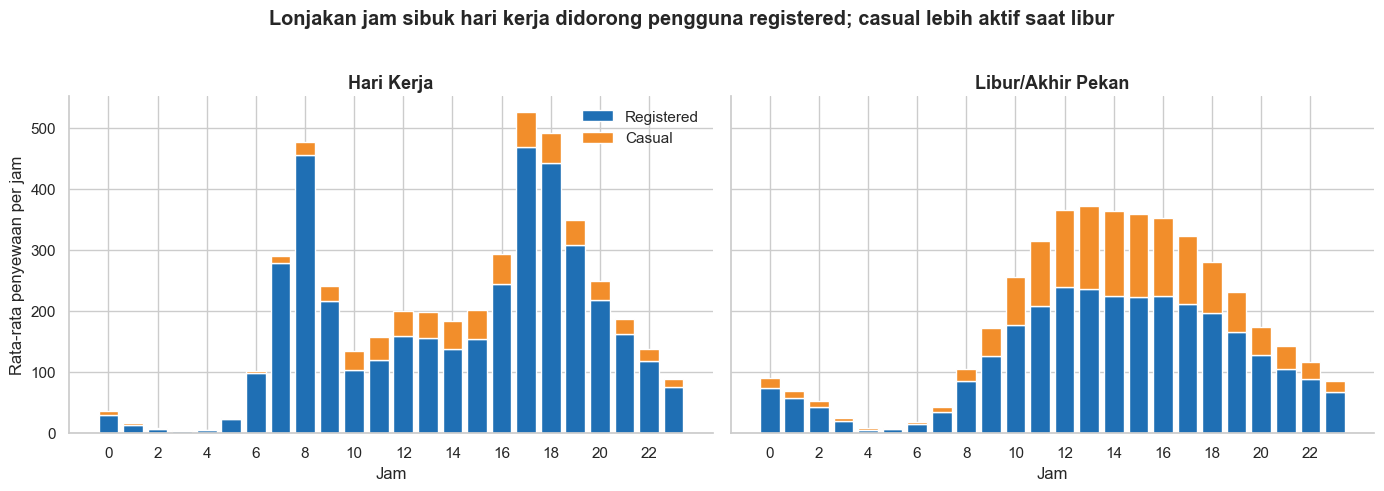

In [39]:
# Siapa yang menyewa pada jam sibuk? Komposisi casual vs registered per jam di masing-masing tipe hari
user_hourly = hour_df.groupby(["workingday", "hour"], observed=True)[["casual", "registered"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, day_type in zip(axes, ["Hari Kerja", "Libur/Akhir Pekan"]):
    data = user_hourly.loc[day_type]
    ax.bar(data.index, data["registered"], color=HIGHLIGHT, label="Registered")
    ax.bar(data.index, data["casual"], bottom=data["registered"], color=SECOND, label="Casual")
    ax.set_title(day_type)
    ax.set_xlabel("Jam")
    ax.set_xticks(range(0, 24, 2))
axes[0].set_ylabel("Rata-rata penyewaan per jam")
axes[0].legend(frameon=False)
fig.suptitle("Lonjakan jam sibuk hari kerja didorong pengguna registered; casual lebih aktif saat libur", fontweight="bold", y=1.02)
plt.tight_layout()

**Insight:**
- Grafik garis memperlihatkan dua pola yang sangat berbeda: **hari kerja** memiliki dua puncak tajam pada **08.00 (±477)** dan **17.00 (±525 sepeda/jam)**, sedangkan **hari libur/akhir pekan** memiliki satu puncak landai di **13.00 (±373 sepeda/jam)**.
- Grafik batang bertumpuk menunjukkan bahwa lonjakan jam sibuk hari kerja hampir seluruhnya berasal dari **pengguna registered** (commuter), sedangkan saat libur porsi **pengguna casual** meningkat signifikan di siang hari.
- Implikasinya, kebutuhan armada tertinggi ada di jam 07.00–09.00 dan 16.00–19.00 pada hari kerja, sehingga redistribusi sepeda harus selesai **sebelum** jam-jam tersebut.

### Pertanyaan 2:
Berapa persen penurunan rata-rata penyewaan sepeda harian saat cuaca hujan/salju ringan dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah selama 2011 – 2012?

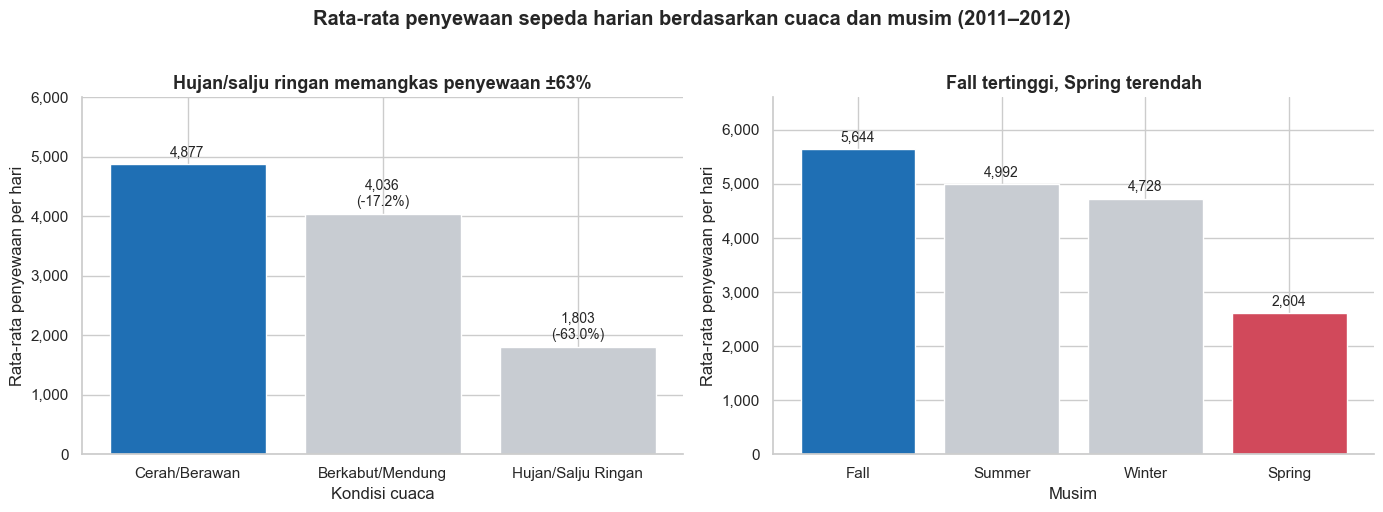

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Cuaca
w = weather_stats["rata2_sewa_harian"]
colors = [HIGHLIGHT if v == w.max() else NEUTRAL for v in w]
bars = axes[0].bar(w.index.astype(str), w.values, color=colors)
for bar, (cat, pct) in zip(bars, weather_stats["selisih_vs_cerah_%"].items()):
    label = f"{bar.get_height():,.0f}" + ("" if pct == 0 else f"\n({pct:+.1f}%)")
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, label, ha="center", va="bottom", fontsize=10)
axes[0].set_title("Hujan/salju ringan memangkas penyewaan ±63%")
axes[0].set_xlabel("Kondisi cuaca")
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_ylim(0, 6000)
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

# (b) Musim (urut dari tertinggi)
s = season_stats["rata2_sewa_harian"]
colors = [HIGHLIGHT if v == s.max() else ("#d1495b" if v == s.min() else NEUTRAL) for v in s]
bars = axes[1].bar(s.index.astype(str), s.values, color=colors)
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, f"{bar.get_height():,.0f}", ha="center", va="bottom", fontsize=10)
axes[1].set_title("Fall tertinggi, Spring terendah")
axes[1].set_xlabel("Musim")
axes[1].set_ylabel("Rata-rata penyewaan per hari")
axes[1].set_ylim(0, 6600)
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

fig.suptitle("Rata-rata penyewaan sepeda harian berdasarkan cuaca dan musim (2011–2012)", fontweight="bold", y=1.02)
plt.tight_layout()

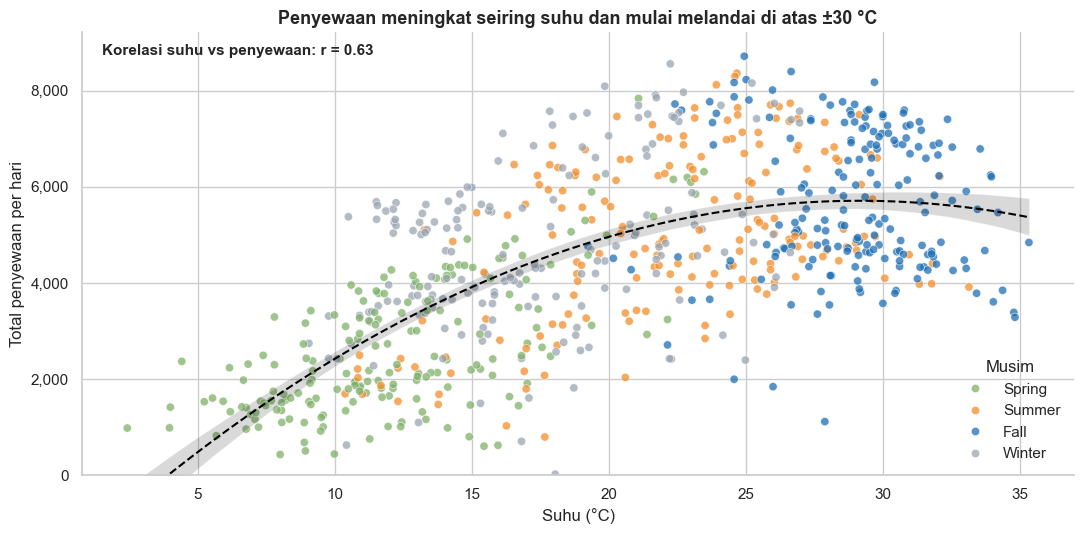

In [41]:
# Hubungan suhu dengan penyewaan, diwarnai berdasarkan musim
fig, ax = plt.subplots(figsize=(11, 5.5))
season_palette = {"Spring": "#7fb069", "Summer": "#f28e2b", "Fall": "#1f6fb4", "Winter": "#9aa5b1"}
sns.scatterplot(data=day_df, x="temp_c", y="total_rentals", hue="season", palette=season_palette, alpha=0.75, ax=ax)
sns.regplot(data=day_df, x="temp_c", y="total_rentals", scatter=False, order=2, color="black",
            line_kws={"linewidth": 1.5, "linestyle": "--"}, ax=ax)
r = day_df["temp_c"].corr(day_df["total_rentals"])
ax.text(0.02, 0.95, f"Korelasi suhu vs penyewaan: r = {r:.2f}", transform=ax.transAxes, fontsize=11, fontweight="bold")
ax.set_title("Penyewaan meningkat seiring suhu dan mulai melandai di atas ±30 °C")
ax.set_xlabel("Suhu (°C)")
ax.set_ylabel("Total penyewaan per hari")
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Musim", frameon=False, loc="lower right")
plt.tight_layout()

**Insight:**
- Dibandingkan cuaca **cerah (±4.877 sepeda/hari)**, penyewaan turun **17,2%** saat berkabut/mendung dan turun drastis **63,0%** saat **hujan/salju ringan (±1.803 sepeda/hari)**.
- Musim **Fall** mencatat rata-rata penyewaan harian **tertinggi (±5.644)**, sedangkan **Spring terendah (±2.604)** — selisih lebih dari 2× lipat.
- Diagram pencar menunjukkan suhu sebagai pendorong utama musiman (r ≈ 0,63): penyewaan naik seiring suhu menghangat hingga ±30 °C, lalu cenderung melandai/menurun pada suhu yang sangat panas.

### Pertanyaan 3:
Berapa tingkat pertumbuhan total penyewaan sepeda tahun 2012 dibandingkan 2011 (YoY) untuk setiap bulan, dan berapa kontribusi pengguna casual vs registered di masing-masing tahun?

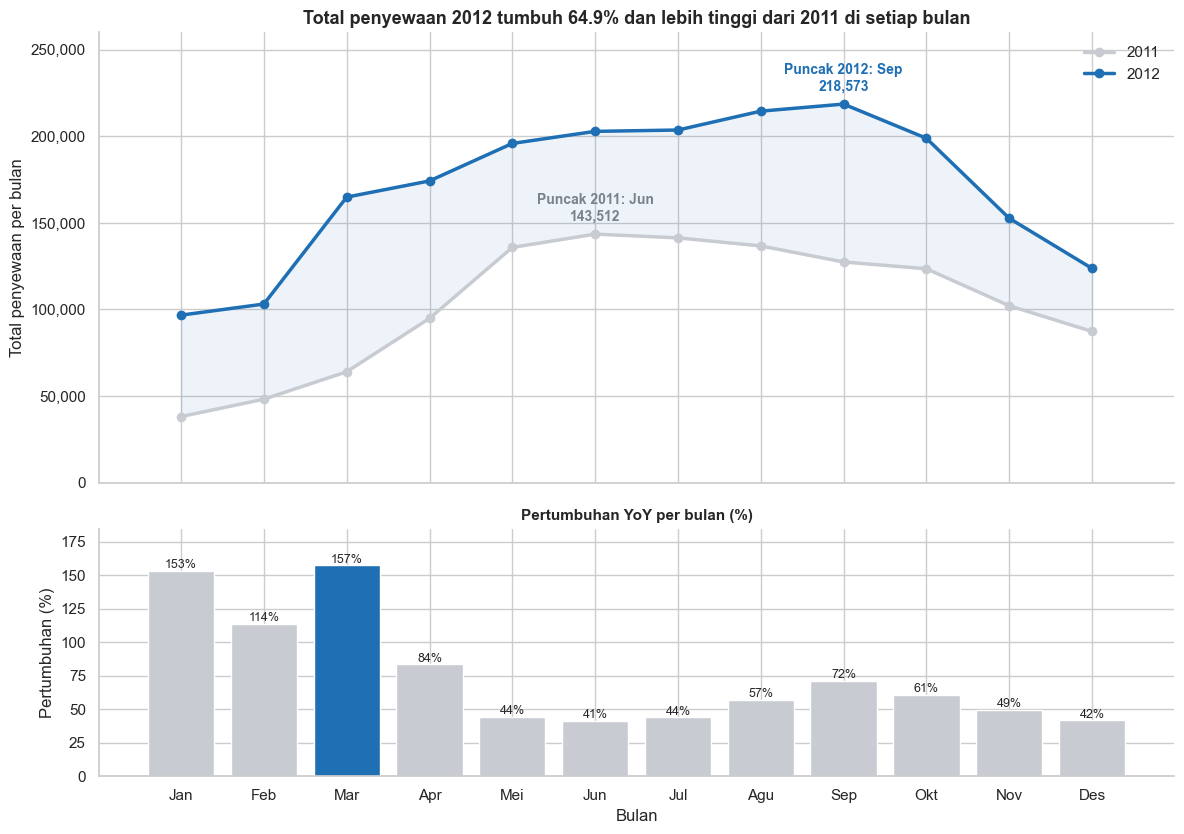

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [2, 1.1]})

months = monthly.index.astype(str)
axes[0].plot(months, monthly[2011], marker="o", color=NEUTRAL, linewidth=2.5, label="2011")
axes[0].plot(months, monthly[2012], marker="o", color=HIGHLIGHT, linewidth=2.5, label="2012")
axes[0].fill_between(months, monthly[2011], monthly[2012], color=HIGHLIGHT, alpha=0.08)
for yr, color in [(2011, "#7a828c"), (2012, HIGHLIGHT)]:
    m = monthly[yr].idxmax()
    axes[0].annotate(f"Puncak {yr}: {m}\n{monthly.loc[m, yr]:,.0f}", (str(m), monthly.loc[m, yr]),
                     textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, fontweight="bold", color=color)
axes[0].set_title(f"Total penyewaan 2012 tumbuh {growth_total:.1f}% dan lebih tinggi dari 2011 di setiap bulan")
axes[0].set_ylabel("Total penyewaan per bulan")
axes[0].set_ylim(0, 260000)
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
axes[0].legend(frameon=False)

g = monthly["growth_yoy_%"]
colors = [HIGHLIGHT if v == g.max() else NEUTRAL for v in g]
bars = axes[1].bar(months, g.values, color=colors)
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"{bar.get_height():.0f}%", ha="center", fontsize=9)
axes[1].set_title("Pertumbuhan YoY per bulan (%)", fontsize=11)
axes[1].set_ylabel("Pertumbuhan (%)")
axes[1].set_xlabel("Bulan")
axes[1].set_ylim(0, 185)
plt.tight_layout()

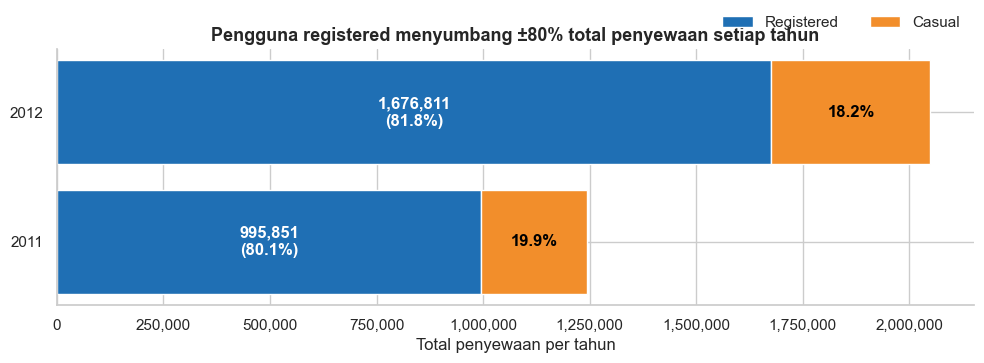

In [43]:
fig, ax = plt.subplots(figsize=(10, 3.8))
years = yearly.index.astype(str)
ax.barh(years, yearly["registered"], color=HIGHLIGHT, label="Registered")
ax.barh(years, yearly["casual"], left=yearly["registered"], color=SECOND, label="Casual")
for i, yr in enumerate(yearly.index):
    reg, cas = yearly.loc[yr, "registered"], yearly.loc[yr, "casual"]
    ax.text(reg / 2, i, f"{reg:,.0f}\n({yearly.loc[yr, '%registered']}%)", ha="center", va="center", color="white", fontweight="bold")
    ax.text(reg + cas / 2, i, f"{yearly.loc[yr, '%casual']}%", ha="center", va="center", color="black", fontweight="bold")
ax.set_title("Pengguna registered menyumbang ±80% total penyewaan setiap tahun")
ax.set_xlabel("Total penyewaan per tahun")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.02), ncol=2)
plt.tight_layout()

**Insight:**
- Total penyewaan 2012 lebih tinggi dibandingkan 2011 **di seluruh 12 bulan**, dengan pertumbuhan tahunan **±64,9%**. Pertumbuhan YoY tertinggi terjadi pada **Maret (+157,4%)**, terendah pada **Juni (+41,3%)**.
- Pola musiman tetap konsisten di kedua tahun: penyewaan rendah di awal & akhir tahun dan tinggi pada pertengahan tahun, dengan puncak bergeser dari Juni (2011) ke September (2012).
- Pengguna **registered** menyumbang **80,1% (2011)** dan **81,8% (2012)** dari total penyewaan, sedangkan pengguna **casual** hanya **19,9% → 18,2%**. Pertumbuhan bisnis sangat bergantung pada member terdaftar.

## Analisis Lanjutan (Opsional)

### Clustering dengan Manual Grouping dan Binning (tanpa algoritma machine learning)

**Tujuan:** mengelompokkan data penyewaan ke dalam segmen yang mudah ditindaklanjuti oleh tim operasional, tanpa menggunakan algoritma machine learning:
1. **Manual grouping – segmen waktu harian:** jam dikelompokkan berdasarkan pemahaman domain (pola commuting) menjadi *Dini Hari, Pagi Sibuk, Siang, Sore Sibuk,* dan *Malam* untuk menentukan prioritas alokasi armada.
2. **Binning – kategori suhu:** suhu (°C) dibagi ke beberapa interval menggunakan `pd.cut()` untuk melihat rentang suhu yang paling ideal bagi penyewaan.
3. **Binning – tingkat permintaan harian:** total penyewaan harian dibagi menjadi *Rendah, Sedang, Tinggi,* dan *Sangat Tinggi* untuk melihat musim dan cuaca yang mendominasi tiap tingkat permintaan.

#### 1. Manual grouping: segmen waktu harian

In [44]:
def time_segment(hour):
    if 0 <= hour <= 5:
        return "Dini Hari (00-05)"
    elif 6 <= hour <= 9:
        return "Pagi Sibuk (06-09)"
    elif 10 <= hour <= 15:
        return "Siang (10-15)"
    elif 16 <= hour <= 19:
        return "Sore Sibuk (16-19)"
    else:
        return "Malam (20-23)"

segment_order = ["Dini Hari (00-05)", "Pagi Sibuk (06-09)", "Siang (10-15)", "Sore Sibuk (16-19)", "Malam (20-23)"]
hour_df["time_segment"] = pd.Categorical(hour_df["hour"].apply(time_segment), categories=segment_order, ordered=True)

segment_stats = hour_df.groupby(["time_segment", "workingday"], observed=True)["total_rentals"].mean().unstack().round(0)
segment_stats

workingday,Hari Kerja,Libur/Akhir Pekan
time_segment,,
Dini Hari (00-05),16.0,43.0
Pagi Sibuk (06-09),278.0,85.0
Siang (10-15),180.0,339.0
Sore Sibuk (16-19),415.0,297.0
Malam (20-23),166.0,130.0


In [45]:
share = hour_df.groupby("time_segment", observed=True)["total_rentals"].sum()
(share / share.sum() * 100).round(1).rename("porsi_total_penyewaan_%")

time_segment
Dini Hari (00-05)      3.2
Pagi Sibuk (06-09)    19.1
Siang (10-15)         30.5
Sore Sibuk (16-19)    33.4
Malam (20-23)         13.7
Name: porsi_total_penyewaan_%, dtype: float64

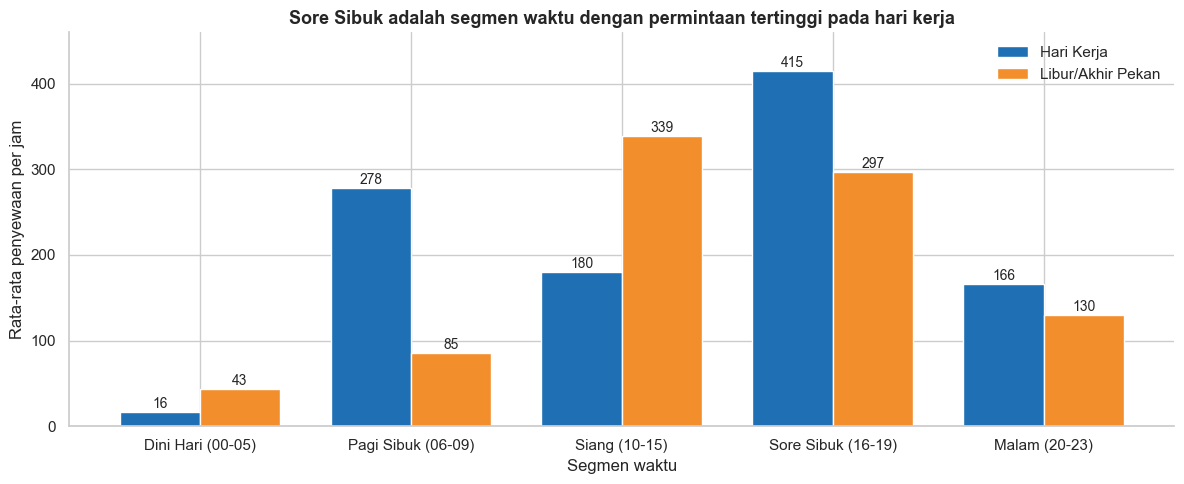

In [46]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(segment_order))
width = 0.38
b1 = ax.bar(x - width / 2, segment_stats["Hari Kerja"], width, color=HIGHLIGHT, label="Hari Kerja")
b2 = ax.bar(x + width / 2, segment_stats["Libur/Akhir Pekan"], width, color=SECOND, label="Libur/Akhir Pekan")
for bars in [b1, b2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5, f"{bar.get_height():.0f}", ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(segment_order)
ax.set_title("Sore Sibuk adalah segmen waktu dengan permintaan tertinggi pada hari kerja")
ax.set_xlabel("Segmen waktu")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_ylim(0, 460)
ax.legend(frameon=False)
plt.tight_layout()

#### 2. Binning: kategori suhu

In [47]:
temp_bins = [0, 10, 20, 30, 42]
temp_labels = ["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"]
day_df["temp_group"] = pd.cut(day_df["temp_c"], bins=temp_bins, labels=temp_labels)

temp_stats = day_df.groupby("temp_group", observed=True).agg(
    jumlah_hari=("date", "count"),
    rata2_sewa_harian=("total_rentals", "mean"),
).round(0)
temp_stats

,jumlah_hari,rata2_sewa_harian
temp_group,,
Dingin (<10°C),60,1678.0
Sejuk (10-20°C),299,3692.0
Hangat (20-30°C),300,5662.0
Panas (>30°C),72,5410.0


#### 3. Binning: tingkat permintaan harian

In [48]:
demand_bins = [0, 2500, 4500, 6500, day_df["total_rentals"].max()]
demand_labels = ["Rendah (<2.500)", "Sedang (2.500-4.500)", "Tinggi (4.500-6.500)", "Sangat Tinggi (>6.500)"]
day_df["demand_level"] = pd.cut(day_df["total_rentals"], bins=demand_bins, labels=demand_labels, include_lowest=True)

day_df["demand_level"].value_counts().sort_index().rename("jumlah_hari")

demand_level
Rendah (<2.500)           144
Sedang (2.500-4.500)      215
Tinggi (4.500-6.500)      231
Sangat Tinggi (>6.500)    141
Name: jumlah_hari, dtype: int64

In [49]:
demand_season = pd.crosstab(day_df["season"], day_df["demand_level"])
demand_season

demand_level,Rendah (<2.500),Sedang (2.500-4.500),Tinggi (4.500-6.500),Sangat Tinggi (>6.500)
season,,,,
Spring,106,57,17,1
Summer,20,50,73,41
Fall,3,38,80,67
Winter,15,70,61,32


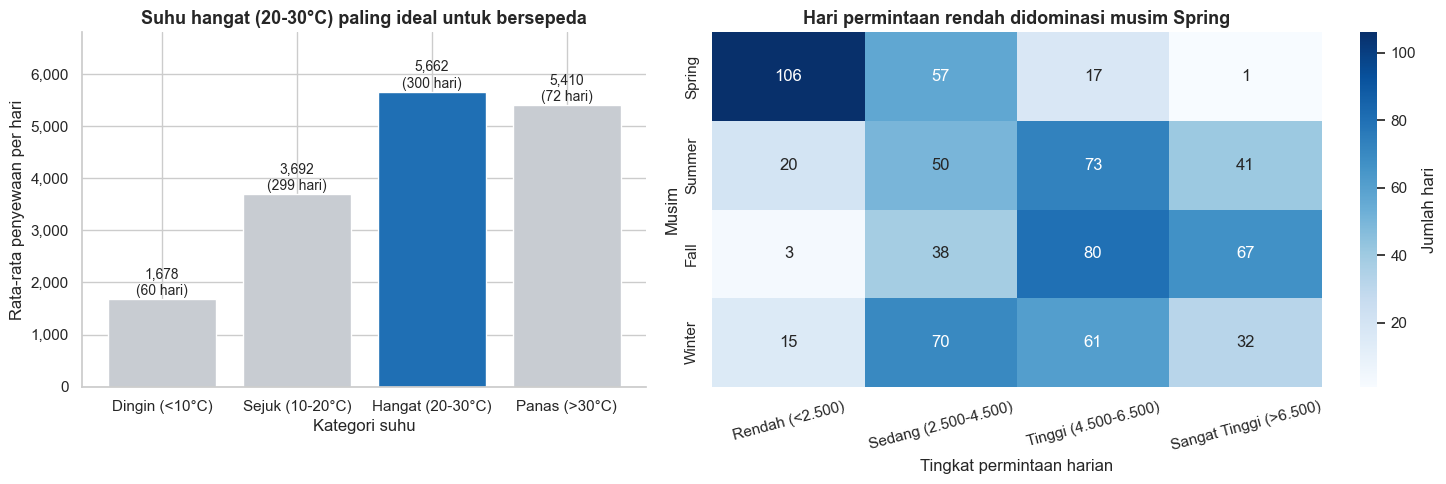

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.35]})

t = temp_stats["rata2_sewa_harian"]
colors = [HIGHLIGHT if v == t.max() else NEUTRAL for v in t]
bars = axes[0].bar(t.index.astype(str), t.values, color=colors)
for bar, n in zip(bars, temp_stats["jumlah_hari"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, f"{bar.get_height():,.0f}\n({n} hari)", ha="center", fontsize=10)
axes[0].set_title("Suhu hangat (20-30°C) paling ideal untuk bersepeda")
axes[0].set_xlabel("Kategori suhu")
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_ylim(0, 6800)
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

sns.heatmap(demand_season, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Jumlah hari"}, ax=axes[1])
axes[1].set_title("Hari permintaan rendah didominasi musim Spring")
axes[1].set_xlabel("Tingkat permintaan harian")
axes[1].set_ylabel("Musim")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()

**Insight:**
- **Segmen waktu (manual grouping):** pada hari kerja, segmen **Sore Sibuk (16–19)** memiliki rata-rata permintaan tertinggi (±415 sepeda/jam), disusul Pagi Sibuk (06–09). Pada hari libur, permintaan terkonsentrasi di segmen **Siang (10–15)**. Segmen **Dini Hari** adalah yang paling sepi di kedua tipe hari.
- **Kategori suhu (binning):** hari dengan suhu **hangat (20–30 °C)** memiliki rata-rata penyewaan tertinggi, sedangkan hari **dingin (<10 °C)** memiliki rata-rata penyewaan terendah.
- **Tingkat permintaan (binning):** hari dengan permintaan **rendah (<2.500)** paling banyak terjadi pada musim **Spring**, sedangkan hari permintaan **sangat tinggi (>6.500)** didominasi musim **Fall** dan **Summer** (seluruhnya terjadi di 2012).
- Segmentasi ini memudahkan tim operasional menentukan prioritas: kapan armada harus siap penuh, kapan bisa dikurangi, dan kapan promosi paling dibutuhkan.

### Menyimpan data bersih untuk dashboard

In [51]:
# Data per jam + kondisi cuaca harian (dari day_df) agar analisis harian di dashboard konsisten dengan notebook
main_data = hour_df.merge(day_df[["date", "weather"]].rename(columns={"weather": "day_weather"}), on="date", how="left")
main_data.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv tersimpan:", main_data.shape)
main_data.head()

main_data.csv tersimpan: (17379, 19)


,instant,date,season,year,month,hour,holiday,weekday,workingday,weather,temp_c,feels_like_c,humidity,windspeed_kmh,casual,registered,total_rentals,time_segment,day_weather
0,1,2011-01-01,Spring,2011,Jan,0,Bukan Libur,Sabtu,Libur/Akhir Pekan,Cerah/Berawan,9.84,14.40,81.0,0.0,3,13,16,Dini Hari (00-05),Berkabut/Mendung
1,2,2011-01-01,Spring,2011,Jan,1,Bukan Libur,Sabtu,Libur/Akhir Pekan,Cerah/Berawan,9.02,13.64,80.0,0.0,8,32,40,Dini Hari (00-05),Berkabut/Mendung
2,3,2011-01-01,Spring,2011,Jan,2,Bukan Libur,Sabtu,Libur/Akhir Pekan,Cerah/Berawan,9.02,13.64,80.0,0.0,5,27,32,Dini Hari (00-05),Berkabut/Mendung
3,4,2011-01-01,Spring,2011,Jan,3,Bukan Libur,Sabtu,Libur/Akhir Pekan,Cerah/Berawan,9.84,14.40,75.0,0.0,3,10,13,Dini Hari (00-05),Berkabut/Mendung
4,5,2011-01-01,Spring,2011,Jan,4,Bukan Libur,Sabtu,Libur/Akhir Pekan,Cerah/Berawan,9.84,14.40,75.0,0.0,0,1,1,Dini Hari (00-05),Berkabut/Mendung


## Conclusion

- **Kesimpulan Pertanyaan 1 (pola per jam):** Selama 2011–2012, puncak penyewaan pada **hari kerja** terjadi di jam **08.00 (±477 sepeda/jam)** dan **17.00 (±525 sepeda/jam, puncak tertinggi)** yang didorong pengguna registered (commuter). Pada **hari libur/akhir pekan**, puncak terjadi di jam **13.00 (±373 sepeda/jam)** dengan tingkat tinggi yang stabil pada 11.00–16.00 karena penggunaan rekreasi. Jam paling sepi adalah **03.00–04.00**.
- **Kesimpulan Pertanyaan 2 (cuaca & musim):** Cuaca **hujan/salju ringan menurunkan rata-rata penyewaan harian sebesar ±63%** dibandingkan cuaca cerah (±1.803 vs ±4.877 sepeda/hari), sedangkan cuaca berkabut/mendung menurunkannya ±17%. Musim **Fall** memiliki rata-rata penyewaan harian tertinggi (**±5.644**), dan **Spring** terendah (**±2.604**), dengan suhu sebagai faktor pendorong utama (r ≈ 0,63; ideal pada 20–30 °C).
- **Kesimpulan Pertanyaan 3 (pertumbuhan & tipe pengguna):** Total penyewaan tumbuh **±64,9%** dari 1,24 juta (2011) menjadi 2,05 juta (2012) dan **setiap bulan di 2012 lebih tinggi** dari 2011 (YoY tertinggi Maret +157%, terendah Juni +41%). Pengguna **registered** menyumbang **±80%** penyewaan di kedua tahun, sementara pengguna **casual** (±18–20%) jauh lebih aktif saat hari libur.

### Rekomendasi (Action Items)
1. **Redistribusi armada berbasis jam:** pada hari kerja, pastikan stasiun di area perkantoran/permukiman terisi penuh **sebelum 07.00 dan 16.00**; pada akhir pekan, geser armada ke area rekreasi/taman sebelum **10.00**.
2. **Jadwal perawatan armada** dilakukan pada jam **00.00–05.00** (segmen Dini Hari) agar tidak mengganggu ketersediaan sepeda.
3. **Perencanaan kapasitas berbasis musim & cuaca:** tambah armada aktif pada musim **Summer–Fall**, dan manfaatkan musim **Spring** serta hari hujan untuk perawatan besar dan rotasi sepeda.
4. **Promosi saat permintaan rendah:** berikan diskon/poin bonus pada musim Spring dan hari berawan/hujan ringan, serta notifikasi prakiraan cuaca di aplikasi untuk menjaga permintaan.
5. **Konversi pengguna casual menjadi member:** luncurkan paket membership akhir pekan/trial pada jam **Siang (10.00–15.00)** di hari libur, saat pengguna casual paling banyak, untuk memperbesar basis pengguna registered yang menjadi mesin pertumbuhan utama.